# **Project Name**    - FedEx EDA



##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Name**            - Prajwal Veerendra H


# **Project Summary -**

# Optimizing FedEx Logistics Through Data Analysis

In an increasingly interconnected global economy, efficient logistics and supply chain management are essential for controlling transportation costs, ensuring timely deliveries, and improving operational efficiency. This project uses Exploratory Data Analysis (EDA) on the SCMS Delivery History dataset to investigate shipment patterns, transportation methods, freight expenses, and delivery performance.

The dataset contains 10,324 records and 33 columns, covering shipment details such as destination countries, vendors, shipment modes, product groups, line item quantities, line item values, package weights, freight costs, and delivery dates. These variables provide insights into logistics operations involving medical products.

The analysis involved inspecting the dataset, identifying missing values, converting relevant date and numerical columns, and creating additional variables such as delivery year, delivery delay, and delivery status. Using Python libraries including Pandas, NumPy, Matplotlib, Seaborn, and Plotly, 15 visualizations were developed to explore country-wise shipment distribution, transportation modes, vendor records, product groups, freight costs, shipment weights, and delivery performance.

The findings showed that South Africa had the highest number of records, Air was the most frequently recorded shipment mode, and ARV was the dominant product group. Out of 10,324 records, 6,324 shipments were delivered on time, 2,814 early, and 1,186 late. Ocean and Truck shipments had higher late-delivery rates than Air shipments. Additionally, shipment weight had a weak positive correlation with freight cost, indicating that factors beyond weight influence transportation expenses.

Based on these findings, the project recommends investigating late deliveries, improving delivery scheduling, evaluating cost-effective transportation options, monitoring high-volume product groups, and improving data quality. These actions may help reduce operational inefficiencies, strengthen logistics planning, and support better business decisions.

In conclusion, this project demonstrates how Exploratory Data Analysis can transform raw logistics data into meaningful insights and practical recommendations. It strengthened practical skills in data cleaning, feature engineering, statistical interpretation, and data visualization while demonstrating the value of data-driven decision-making in supply chain management. Although the source dataset concerns medical-product supply chain operations rather than exclusively FedEx operations, the analytical methods can be applied to broader logistics optimization challenges.

# **GitHub Link -**

[LINK](https://github.com/Prajwal-VH?tab=repositories)

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [3]:

# Import libraries for FedEx Logistics EDA

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
import warnings

# Suppress warning messages
warnings.filterwarnings("ignore")

# Set visualization style
sns.set_style("whitegrid")

# Display plots within Jupyter Notebook
%matplotlib inline


In [4]:
# Reading dataset
df = pd.read_csv("SCMS_Delivery_History_Dataset.csv")

In [7]:
#check first ten rows of the dataset
df.head(10)

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN
5,23,112-NG-T01,Pre-PQ Process,SCMS-87,ASN-57,Nigeria,PMO - US,Direct Drop,EXW,Air,...,240,416,2225.60,5.35,0.02,"Aurobindo Unit III, India",Yes,504,5920.42,NaN
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,...,90,135,4374.00,32.40,0.36,MSD South Granville Australia,Yes,328,Freight Included in Commodity Cost,NaN
7,45,109-TZ-T01,Pre-PQ Process,SCMS-140,ASN-94,Tanzania,PMO - US,Direct Drop,EXW,Air,...,60,16667,60834.55,3.65,0.06,"Aurobindo Unit III, India",Yes,1478,6212.41,NaN
8,46,112-NG-T01,Pre-PQ Process,SCMS-156,ASN-93,Nigeria,PMO - US,Direct Drop,EXW,Air,...,60,273,532.35,1.95,0.03,"Aurobindo Unit III, India",No,See ASN-93 (ID#:1281),See ASN-93 (ID#:1281),NaN
9,47,110-ZM-T01,Pre-PQ Process,SCMS-165,ASN-199,Zambia,PMO - US,Direct Drop,CIP,Air,...,120,2800,115080.00,41.10,0.34,ABBVIE (Abbott) St. P'burg USA,Yes,643,Freight Included in Commodity Cost,NaN


### Check the dataset structure

In [8]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information and data types
df.info()

Dataset shape: (10324, 33)

Column names:
['ID', 'Project Code', 'PQ #', 'PO / SO #', 'ASN/DN #', 'Country', 'Managed By', 'Fulfill Via', 'Vendor INCO Term', 'Shipment Mode', 'PQ First Sent to Client Date', 'PO Sent to Vendor Date', 'Scheduled Delivery Date', 'Delivered to Client Date', 'Delivery Recorded Date', 'Product Group', 'Sub Classification', 'Vendor', 'Item Description', 'Molecule/Test Type', 'Brand', 'Dosage', 'Dosage Form', 'Unit of Measure (Per Pack)', 'Line Item Quantity', 'Line Item Value', 'Pack Price', 'Unit Price', 'Manufacturing Site', 'First Line Designation', 'Weight (Kilograms)', 'Freight Cost (USD)', 'Line Item Insurance (USD)']
<class 'pandas.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  str    
 2   PQ

### Check missing values

In [10]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing,
    'Percentage (%)': (missing / len(df) * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values('Missing Values', ascending=False)

display(missing_summary)

,Missing Values,Percentage (%)
Dosage,1736,16.82
Shipment Mode,360,3.49
Line Item Insurance (USD),287,2.78


### Check duplicates

In [11]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check duplicate IDs
print("Duplicate IDs:", df['ID'].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


### Visualizing missing values

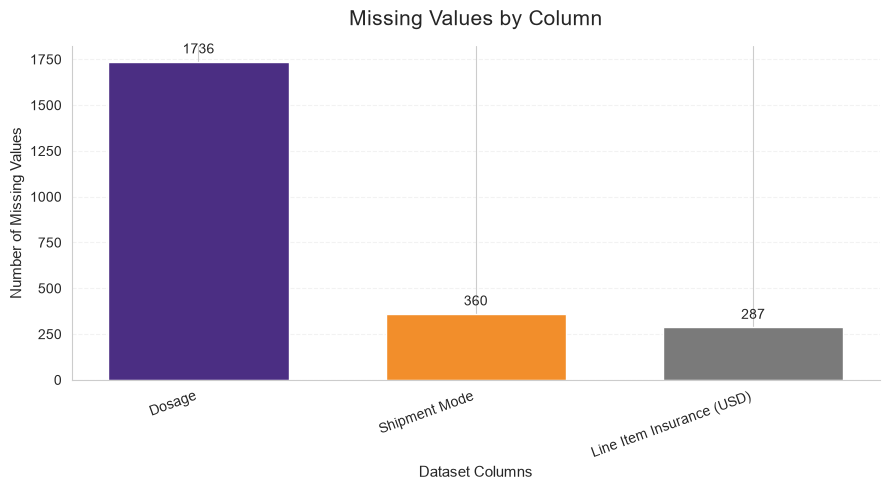

In [12]:
# Calculate missing values and sort in descending order
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(
    ascending=False
)

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    missing_data.index,
    missing_data.values,
    color=['#4B2E83', '#F28E2B', '#7A7A7A'],
    width=0.65
)

# Display counts above bars
ax.bar_label(bars, padding=4, fontsize=10)

# Chart formatting
ax.set_title('Missing Values by Column', fontsize=15, pad=15)
ax.set_xlabel('Dataset Columns', fontsize=11)
ax.set_ylabel('Number of Missing Values', fontsize=11)

plt.xticks(rotation=20, ha='right')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### What did you learn about your dataset?

The FedEx dataset contains 10,324 records and 33 columns, providing detailed information about shipment operations, procurement activities, product distribution, and supply chain management. It includes identification fields such as IDs, project codes, purchase order numbers, and shipment documentation numbers. Operational details include destination countries, vendors, shipment modes, fulfilment methods, manufacturing sites, and scheduled and actual delivery dates.

The dataset also contains numerical variables such as line item quantities, line item values, pack prices, unit prices, freight costs, and insurance costs. These variables can be used to analyse shipment volumes, product pricing, transportation expenses, and overall logistics costs. The delivery date columns also help evaluate delivery performance by comparing scheduled delivery dates with actual delivery dates to identify potential delays.

During the initial data inspection, I identified missing values in three columns: Dosage (1,736 missing values), Shipment Mode (360 missing values), and Line Item Insurance (USD) (287 missing values). I also observed that the Weight (Kilograms) and Freight Cost (USD) columns are stored as strings rather than numerical values, so they require cleaning and conversion before numerical analysis.

Additionally, the dataset contains no duplicate rows or duplicate IDs, which supports a more reliable analysis of the available records. Overall, the FedEx dataset is suitable for exploratory data analysis of shipment patterns, transportation methods, freight costs, product distribution, and delivery performance. These insights can help identify opportunities to reduce logistics expenses, improve operational efficiency, and support data-driven supply chain decisions.

### Inspect the data

In [13]:
# Inspect the columns that need cleaning

print("Weight samples:")
print(df['Weight (Kilograms)'].value_counts(dropna=False).head(10))

print("\nFreight cost samples:")
print(df['Freight Cost (USD)'].value_counts(dropna=False).head(10))

print("\nDate samples:")
print(df[
    ['Scheduled Delivery Date',
     'Delivered to Client Date',
     'Delivery Recorded Date']
].head(10))

Weight samples:
Weight (Kilograms)
Weight Captured Separately    1507
2                               29
6                               26
1                               23
60                              20
5                               20
4                               19
3                               18
14                              17
12                              17
Name: count, dtype: int64

Freight cost samples:
Freight Cost (USD)
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
9736.1                                  36
6147.18                                 27
See DN-304 (ID#:10589)                  16
7445.8                                  16
13398.06                                16
9341.49                                 15
See ASN-32231 (ID#:13648)               14
See ASN-31750 (ID#:19272)               14
Name: count, dtype: int64

Date samples:
  Scheduled Delivery Date Delivered to Client Date Delivery Recorded Date
0 

### Clean the FedEx dataset

In [14]:

# Create a copy for cleaning
df_clean = df.copy()

# 1. Convert shipment weight into numeric values
df_clean['Weight_kg_numeric'] = pd.to_numeric(
    df_clean['Weight (Kilograms)'],
    errors='coerce'
)

# 2. Convert freight cost into numeric values
df_clean['Freight_Cost_USD_numeric'] = pd.to_numeric(
    df_clean['Freight Cost (USD)'],
    errors='coerce'
)

# 3. Convert date columns into datetime format
date_columns = [
    'PQ First Sent to Client Date',
    'PO Sent to Vendor Date',
    'Scheduled Delivery Date',
    'Delivered to Client Date',
    'Delivery Recorded Date'
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format='%d-%b-%y',
        errors='coerce'
    )

# 4. Check the cleaning results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values in newly cleaned columns:")
print(df_clean[
    ['Weight_kg_numeric', 'Freight_Cost_USD_numeric']
].isnull().sum())

print("\nDate conversion results:")
print(df_clean[date_columns].isnull().sum())

print("\nCleaned data preview:")
display(df_clean[
    ['Weight (Kilograms)', 'Weight_kg_numeric',
     'Freight Cost (USD)', 'Freight_Cost_USD_numeric',
     'Scheduled Delivery Date', 'Delivered to Client Date']
].head())

Original dataset shape: (10324, 33)
Cleaned dataset shape: (10324, 35)

Missing values in newly cleaned columns:
Weight_kg_numeric           3952
Freight_Cost_USD_numeric    4126
dtype: int64

Date conversion results:
PQ First Sent to Client Date    10324
PO Sent to Vendor Date          10324
Scheduled Delivery Date             0
Delivered to Client Date            0
Delivery Recorded Date              0
dtype: int64

Cleaned data preview:


,Weight (Kilograms),Weight_kg_numeric,Freight Cost (USD),Freight_Cost_USD_numeric,Scheduled Delivery Date,Delivered to Client Date
0,13,13.0,780.34,780.34,2006-06-02,2006-06-02
1,358,358.0,4521.5,4521.50,2006-11-14,2006-11-14
2,171,171.0,1653.78,1653.78,2006-08-27,2006-08-27
3,1855,1855.0,16007.06,16007.06,2006-09-01,2006-09-01
4,7590,7590.0,45450.08,45450.08,2006-08-11,2006-08-11


In [15]:
# 1. Inspect the original procurement date values
print("PQ First Sent to Client Date:")
print(df['PQ First Sent to Client Date'].value_counts(dropna=False).head(15))

print("\nPO Sent to Vendor Date:")
print(df['PO Sent to Vendor Date'].value_counts(dropna=False).head(15))

# 2. Inspect nonnumeric weight entries
weight_numeric = pd.to_numeric(df['Weight (Kilograms)'], errors='coerce')
print("\nExamples of nonnumeric weight entries:")
print(df.loc[
    weight_numeric.isna(), 'Weight (Kilograms)'
].value_counts(dropna=False).head(15))

# 3. Inspect nonnumeric freight cost entries
freight_numeric = pd.to_numeric(df['Freight Cost (USD)'], errors='coerce')
print("\nExamples of nonnumeric freight cost entries:")
print(df.loc[
    freight_numeric.isna(), 'Freight Cost (USD)'
].value_counts(dropna=False).head(15))

PQ First Sent to Client Date:
PQ First Sent to Client Date
Pre-PQ Process       2476
Date Not Captured     205
9/11/14               205
7/11/13               173
4/30/14               123
11/6/09                98
11/21/11               90
3/10/11                89
3/18/10                78
8/31/10                75
2/10/10                72
3/18/13                64
10/13/10               62
12/13/12               56
10/21/13               53
Name: count, dtype: int64

PO Sent to Vendor Date:
PO Sent to Vendor Date
N/A - From RDC       5404
Date Not Captured     328
8/27/14                80
3/19/10                78
8/29/14                76
10/9/14                71
12/2/13                67
9/24/10                53
2/20/15                43
5/11/15                40
3/24/11                34
12/14/10               34
4/2/09                 32
3/28/11                32
6/17/10                32
Name: count, dtype: int64

Examples of nonnumeric weight entries:
Weight (Kilograms)
We

In [16]:
# Convert procurement dates using the observed month/day/year format
procurement_date_columns = [
    'PQ First Sent to Client Date',
    'PO Sent to Vendor Date'
]

for col in procurement_date_columns:
    df_clean[col] = pd.to_datetime(
        df[col],
        format='%m/%d/%y',
        errors='coerce'
    )

# Check how many dates were successfully converted
for col in procurement_date_columns:
    print(f"\n{col}")
    print("Valid dates:", df_clean[col].notna().sum())
    print("Missing or non-date entries:", df_clean[col].isna().sum())
    print("Sample converted dates:")
    print(df_clean[col].dropna().head())

# Verify all five date columns
date_columns = [
    'PQ First Sent to Client Date',
    'PO Sent to Vendor Date',
    'Scheduled Delivery Date',
    'Delivered to Client Date',
    'Delivery Recorded Date'
]

print("\nMissing values across all date columns:")
print(df_clean[date_columns].isna().sum())


PQ First Sent to Client Date
Valid dates: 7643
Missing or non-date entries: 2681
Sample converted dates:
2681   2009-11-18
2682   2013-05-03
2683   2014-08-19
2684   2012-01-06
2685   2013-02-22
Name: PQ First Sent to Client Date, dtype: datetime64[us]

PO Sent to Vendor Date
Valid dates: 4592
Missing or non-date entries: 5732
Sample converted dates:
9    2006-11-13
10   2006-12-01
13   2006-12-22
15   2007-01-10
18   2007-04-12
Name: PO Sent to Vendor Date, dtype: datetime64[us]

Missing values across all date columns:
PQ First Sent to Client Date    2681
PO Sent to Vendor Date          5732
Scheduled Delivery Date            0
Delivered to Client Date           0
Delivery Recorded Date             0
dtype: int64


In [17]:
# Create delivery delay in days
df_clean['Lead Time Days'] = (
    df_clean['Delivered to Client Date']
    - df_clean['Scheduled Delivery Date']
).dt.days

# Create delivery year for trend analysis
df_clean['Delivery Year'] = (
    df_clean['Delivered to Client Date'].dt.year
)

# Classify delivery performance
df_clean['Delivery Status'] = np.select(
    [
        df_clean['Lead Time Days'] > 0,
        df_clean['Lead Time Days'] < 0
    ],
    [
        'Late',
        'Early'
    ],
    default='On Time'
)

# Verify the new features
print("Lead Time Days summary:")
print(df_clean['Lead Time Days'].describe())

print("\nDelivery Status counts:")
print(df_clean['Delivery Status'].value_counts())

print("\nDelivery Year range:")
print(df_clean['Delivery Year'].min(), "to",
      df_clean['Delivery Year'].max())

display(df_clean[
    ['Scheduled Delivery Date',
     'Delivered to Client Date',
     'Lead Time Days',
     'Delivery Year',
     'Delivery Status']
].head(10))

Lead Time Days summary:
count    10324.000000
mean        -6.023537
std         27.233640
min       -372.000000
25%         -3.000000
50%          0.000000
75%          0.000000
max        192.000000
Name: Lead Time Days, dtype: float64

Delivery Status counts:
Delivery Status
On Time    6324
Early      2814
Late       1186
Name: count, dtype: int64

Delivery Year range:
2006 to 2015


,Scheduled Delivery Date,Delivered to Client Date,Lead Time Days,Delivery Year,Delivery Status
0,2006-06-02,2006-06-02,0,2006,On Time
1,2006-11-14,2006-11-14,0,2006,On Time
2,2006-08-27,2006-08-27,0,2006,On Time
3,2006-09-01,2006-09-01,0,2006,On Time
4,2006-08-11,2006-08-11,0,2006,On Time
5,2006-09-28,2006-09-28,0,2006,On Time
6,2007-01-08,2007-01-08,0,2007,On Time
7,2006-11-24,2006-11-24,0,2006,On Time
8,2006-12-07,2006-12-07,0,2006,On Time
9,2007-01-30,2007-01-30,0,2007,On Time


## What all manipulations have you done and insights you found?

I began by loading and inspecting the FedEx dataset, which contains 10,324 records and 33 original columns. I checked for duplicate records and duplicate IDs and found none. I then created a separate copy of the dataset for cleaning, preserving the original data.

Next, I converted the **Weight (Kilograms)** and **Freight Cost (USD)** columns into numeric formats so they could be used for statistical analysis. Since these columns contain descriptive entries such as “Weight Captured Separately” and “Freight Included in Commodity Cost,” these entries were converted to missing values in the new numeric columns, while the original columns were retained.

I converted the three delivery-related date columns—Scheduled Delivery Date, Delivered to Client Date, and Delivery Recorded Date—into datetime formats. I also converted the two procurement date columns using their observed month/day/year format. Entries such as “Pre-PQ Process,” “Date Not Captured,” and “N/A - From RDC” were treated as missing dates rather than being assigned incorrect dates.

To analyze delivery performance, I engineered three new features: **Lead Time Days**, calculated as the difference between the actual and scheduled delivery dates; **Delivery Year**, extracted from the actual delivery date; and **Delivery Status**, which classifies each record as Early, On Time, or Late.

The initial analysis revealed that **6,324 deliveries (61.3%) were on time, 2,814 (27.3%) were early, and 1,186 (11.5%) were late**. The average delivery delay was approximately −6 days, indicating that deliveries occurred earlier than scheduled on average. However, the delay ranged from −372 to +192 days, suggesting that some records require further investigation.

These findings provide an initial understanding of delivery performance and establish a foundation for further analysis of shipment distribution, transportation modes, freight costs, vendors, and delivery delays. The remaining analyses will help identify operational inefficiencies and opportunities to improve logistics performance and cost management.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

## Chart 1: Shipment Distribution by Country

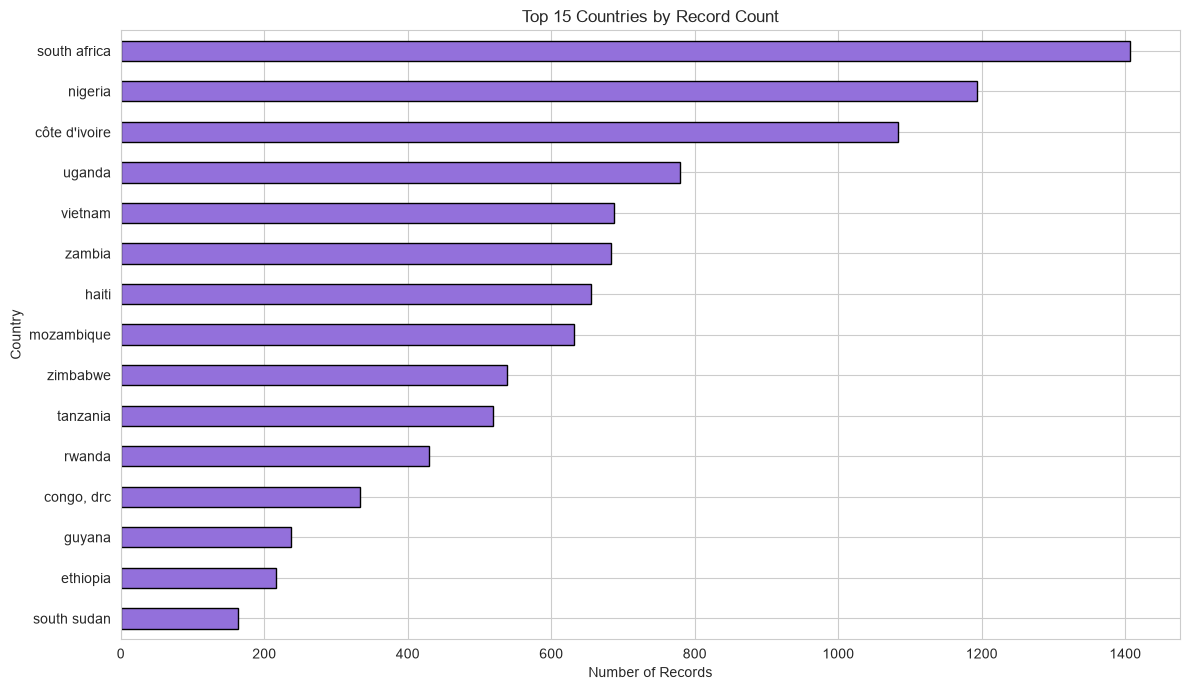

Top 15 countries by record count:
Country_Standardized
south africa     1406
nigeria          1194
côte d'ivoire    1083
uganda            779
vietnam           688
zambia            683
haiti             655
mozambique        631
zimbabwe          538
tanzania          519
rwanda            430
congo, drc        333
guyana            237
ethiopia          216
south sudan       164
Name: count, dtype: int64[pyarrow]


In [18]:
# Chart 1: Shipment Distribution by Country

# Standardize country names for consistent grouping
df_clean['Country_Standardized'] = (
    df_clean['Country']
    .astype('string')
    .str.strip()
    .str.lower()
)

# Find the top 15 countries by record count
country_counts = (
    df_clean['Country_Standardized']
    .value_counts()
    .head(15)
    .sort_values(ascending=True)
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))
country_counts.plot(
    kind='barh',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Top 15 Countries by Record Count')
plt.xlabel('Number of Records')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

# Display counts for accurate interpretation
print("Top 15 countries by record count:")
print(country_counts.sort_values(ascending=False))

##### 1. Why did you pick the specific chart?

A horizontal bar chart makes it easy to compare shipment record counts across countries and identify the highest-volume locations.

##### 2. What is/are the insight(s) found from the chart?

South Africa leads with 1,406 records, followed by Nigeria (1,194) and Côte d'Ivoire (1,083). This indicates a concentration of records in these countries.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these findings can help prioritize logistics resources in high-volume countries. However, allocating too few resources to lower-volume countries could affect service quality. Record counts alone do not establish profitability or negative growth.

## Chart 2: Shipment Mode Distribution

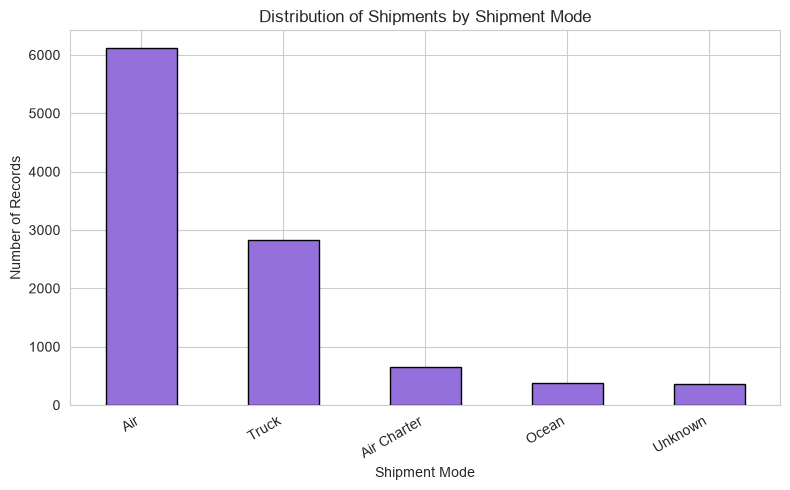

Shipment mode counts:
Shipment Mode
Air            6113
Truck          2830
Air Charter     650
Ocean           371
Unknown         360
Name: count, dtype: int64


In [19]:
# Chart 2: Shipment Mode Distribution

shipment_mode_counts = (
    df_clean['Shipment Mode']
    .fillna('Unknown')
    .value_counts()
)

plt.figure(figsize=(8, 5))
shipment_mode_counts.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Distribution of Shipments by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Number of Records')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print("Shipment mode counts:")
print(shipment_mode_counts)

##### 1. Why did you pick the specific chart?

A bar chart makes it easy to compare shipment volumes across transportation modes and identify the most frequently used mode.

##### 2. What is/are the insight(s) found from the chart?

Air is the most common mode with 6,113 records, followed by Truck with 2,830. Ocean has the fewest records (371), while 360 records have an unknown shipment mode.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these findings can help optimize transportation planning and resource allocation. Heavy reliance on air transport may increase logistics costs, while missing mode information can limit accurate performance comparisons.

## Chart 3: Product Group Distribution

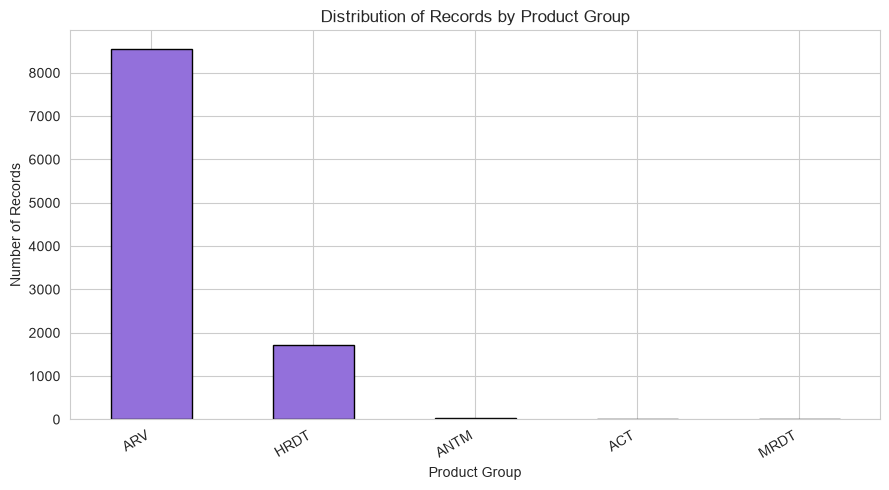

Product group counts:
Product Group
ARV     8550
HRDT    1728
ANTM      22
ACT       16
MRDT       8
Name: count, dtype: int64


In [20]:
# Chart 3: Product Group Distribution

product_group_counts = (
    df_clean['Product Group']
    .value_counts()
)

plt.figure(figsize=(9, 5))
product_group_counts.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Distribution of Records by Product Group')
plt.xlabel('Product Group')
plt.ylabel('Number of Records')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print("Product group counts:")
print(product_group_counts)

##### 1. Why did you pick the specific chart?

A bar chart clearly compares record counts across product groups and highlights the dominant categories.

##### 2. What is/are the insight(s) found from the chart?

ARV dominates with 8,550 records, followed by HRDT with 1,728. The remaining three groups together account for only 46 records.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Yes, these insights help prioritize inventory planning and logistics resources for high-volume product groups. However, the strong concentration in ARV may create planning risks if resources for smaller groups are overlooked; record counts alone do not establish profitability or demand.

## Chart 4: Top 10 Vendors by Record Count

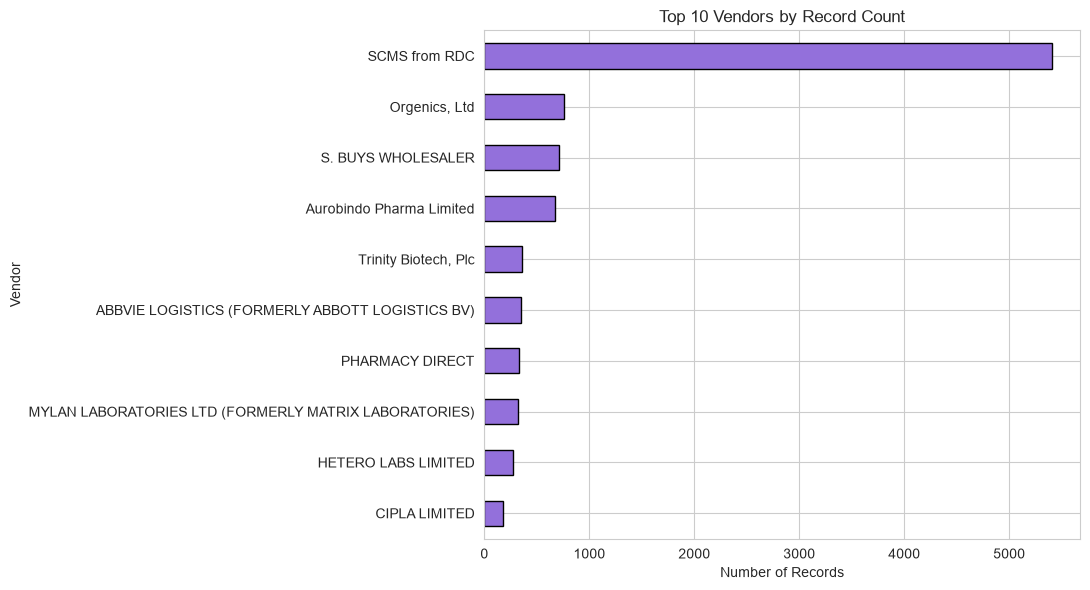

Top 10 vendors by record count:
Vendor
SCMS from RDC                                            5404
Orgenics, Ltd                                             754
S. BUYS WHOLESALER                                        715
Aurobindo Pharma Limited                                  668
Trinity Biotech, Plc                                      356
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)           347
PHARMACY DIRECT                                           326
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORATORIES)     317
HETERO LABS LIMITED                                       277
CIPLA LIMITED                                             175
Name: count, dtype: int64


In [21]:
# Chart 4: Top 10 Vendors by Record Count

vendor_counts = (
    df_clean['Vendor']
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))
vendor_counts.plot(
    kind='barh',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Top 10 Vendors by Record Count')
plt.xlabel('Number of Records')
plt.ylabel('Vendor')
plt.tight_layout()
plt.show()

print("Top 10 vendors by record count:")
print(vendor_counts.sort_values(ascending=False))

##### 1. Why did you pick the specific chart?

A horizontal bar chart makes it easy to compare vendor record counts and identify the vendors with the highest representation.

##### 2. What is/are the insight(s) found from the chart?

SCMS from RDC leads with 5,404 records, far exceeding Orgenics, Ltd (754) and S. BUYS WHOLESALER (715). This indicates a strong concentration of records under SCMS from RDC.

##### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the findings can help prioritize vendor coordination and monitor supply-chain operations. However, the high concentration under SCMS from RDC may indicate dependency or a reporting-channel difference, so the vendor's role should be verified before concluding that supplier dependency is a risk.

## BiVariate
## Chart 5: Freight Cost by Shipment Mode

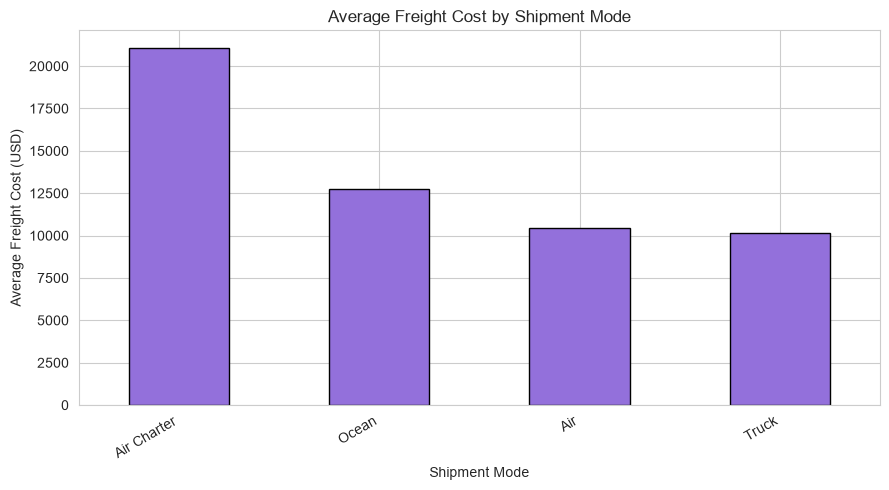

Average freight cost by shipment mode (USD):
Shipment Mode
Air Charter    21052.14
Ocean          12733.08
Air            10458.96
Truck          10176.41
Name: Freight_Cost_USD_numeric, dtype: float64

Number of numeric freight-cost records per mode:
Shipment Mode
Air            4115
Air Charter     424
Ocean           282
Truck          1166
Name: Freight_Cost_USD_numeric, dtype: int64


In [22]:
# Chart 5: Average Freight Cost by Shipment Mode

freight_data = df_clean.dropna(
    subset=['Freight_Cost_USD_numeric', 'Shipment Mode']
)

average_freight = (
    freight_data.groupby('Shipment Mode')['Freight_Cost_USD_numeric']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
average_freight.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Average Freight Cost by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Average Freight Cost (USD)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print("Average freight cost by shipment mode (USD):")
print(average_freight.round(2))
print("\nNumber of numeric freight-cost records per mode:")
print(
    freight_data.groupby('Shipment Mode')['Freight_Cost_USD_numeric']
    .count()
)

**1. Why did you pick the specific chart?**

I selected a bar chart to compare the average freight cost across different shipment modes and identify which modes are more expensive.

**2. What is/are the insight(s) found from the chart?**

Air Charter had the highest average freight cost at USD 21,052.14, followed by Ocean at USD 12,733.08, Air at USD 10,458.96, and Truck at USD 10,176.41.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business identify cost-saving opportunities when planning transportation. The high average cost of Air Charter may increase logistics expenses, while choosing more economical shipment modes when delivery urgency permits could reduce costs. However, shipment distance, weight, and urgency should also be considered before changing shipment modes.

## Chart 6 — Shipment Weight vs. Freight Cost

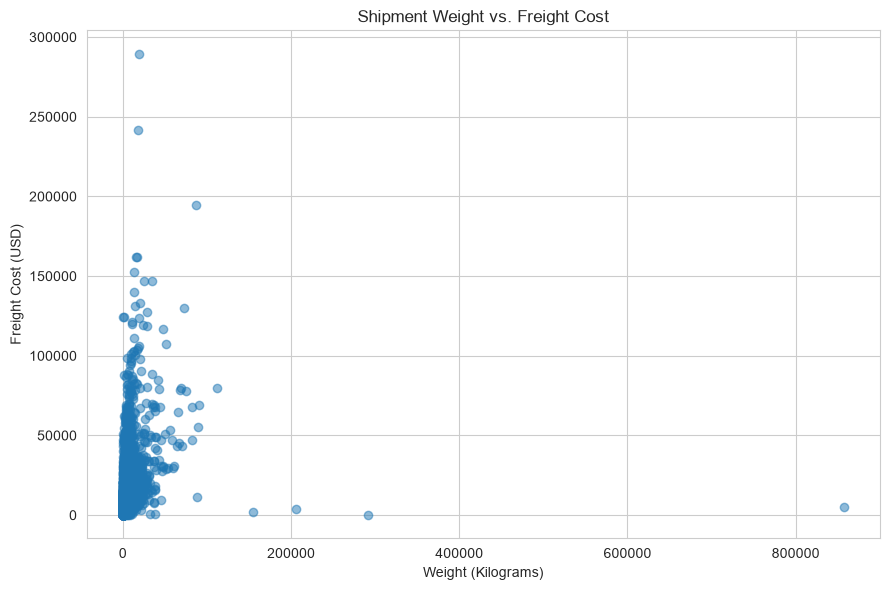

Valid shipment records plotted: 6174
Correlation between weight and freight cost: 0.232


In [23]:
# Chart 6: Shipment Weight vs. Freight Cost

weight_freight_data = df_clean.dropna(
    subset=['Weight_kg_numeric', 'Freight_Cost_USD_numeric']
)

weight_freight_data = weight_freight_data[
    (weight_freight_data['Weight_kg_numeric'] > 0) &
    (weight_freight_data['Freight_Cost_USD_numeric'] >= 0)
]

plt.figure(figsize=(9, 6))

plt.scatter(
    weight_freight_data['Weight_kg_numeric'],
    weight_freight_data['Freight_Cost_USD_numeric'],
    alpha=0.5
)

plt.title('Shipment Weight vs. Freight Cost')
plt.xlabel('Weight (Kilograms)')
plt.ylabel('Freight Cost (USD)')
plt.tight_layout()
plt.show()

print("Valid shipment records plotted:", len(weight_freight_data))

print(
    "Correlation between weight and freight cost:",
    round(
        weight_freight_data[
            ['Weight_kg_numeric', 'Freight_Cost_USD_numeric']
        ].corr().iloc[0, 1],
        3
    )
)

**1. Why did you pick the specific chart?**

I selected a scatter plot to examine the relationship between shipment weight and freight cost. It helps identify patterns, variations, and unusual shipments in the FedEx dataset.

**2. What is/are the insight(s) found from the chart?**

The chart includes 6,174 valid shipment records. The correlation between shipment weight and freight cost is 0.232, indicating a weak positive relationship. This means heavier shipments tend to have slightly higher freight costs, but weight alone does not explain the overall cost.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business improve freight cost estimation and transportation planning by considering shipment weight along with other factors. The weak relationship suggests that relying only on weight to estimate freight costs may lead to inaccurate budgets and unexpected expenses. Considering shipment mode, distance, and delivery urgency can support better cost control.

## Chart 7: Delivery Status Distribution

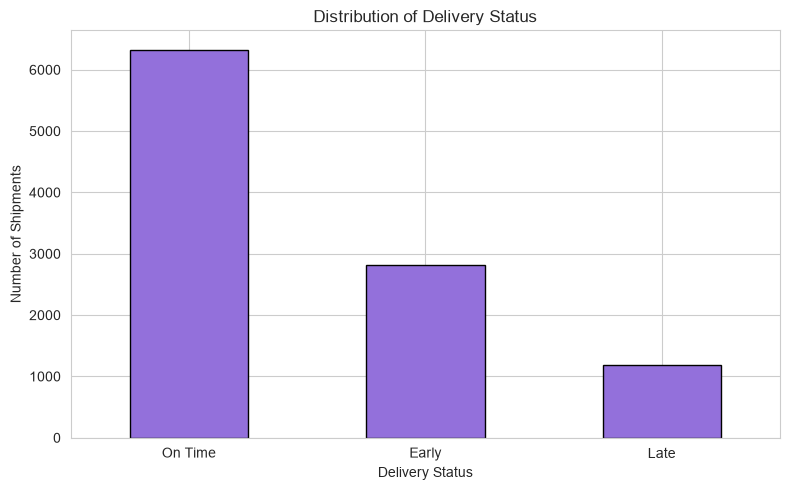

Delivery Status Counts:
Delivery Status
On Time    6324
Early      2814
Late       1186
Name: count, dtype: int64

Delivery Status Percentages:
Delivery Status
On Time    61.26
Early      27.26
Late       11.49
Name: count, dtype: float64


In [24]:
# Chart 7: Delivery Status Distribution

delivery_status_counts = df_clean['Delivery Status'].value_counts()

plt.figure(figsize=(8, 5))

delivery_status_counts.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Distribution of Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Shipments')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Delivery Status Counts:")
print(delivery_status_counts)

print("\nDelivery Status Percentages:")
print((delivery_status_counts / len(df_clean) * 100).round(2))

**1. Why did you pick the specific chart?**

I selected a bar chart to compare the number of shipments delivered early, on time, and late. It helps evaluate overall delivery performance in the FedEx dataset.

**2. What is/are the insight(s) found from the chart?**

Out of 10,324 shipments, 6,324 were delivered on time, 2,814 were delivered early, and 1,186 were delivered late. This shows that most shipments were delivered on time, while approximately 11.5% experienced delays.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business monitor delivery performance and identify opportunities to reduce delays. Late deliveries may lead to customer dissatisfaction, additional logistics costs, and reduced operational efficiency. Investigating the causes

## Chart 8 — Delivery Status by Shipment Mode

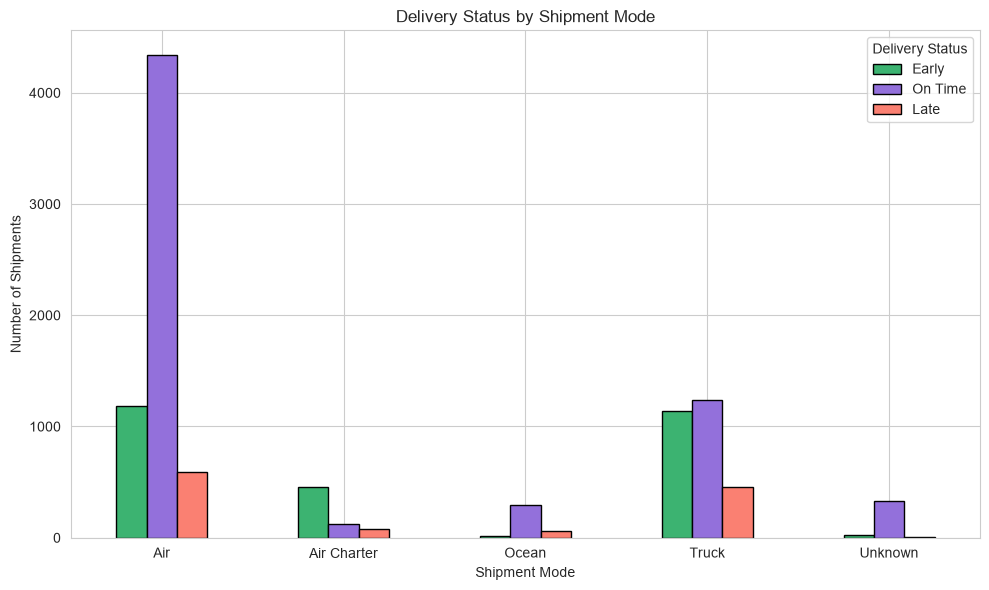

Delivery Status by Shipment Mode:
Delivery Status  Early  On Time  Late
Shipment Mode                        
Air               1183     4343   587
Air Charter        452      123    75
Ocean               15      291    65
Truck             1137     1238   455
Unknown             27      329     4

Late Delivery Percentage by Shipment Mode:
Shipment Mode
Air             9.60
Air Charter    11.54
Ocean          17.52
Truck          16.08
Unknown         1.11
dtype: float64


In [25]:
# Chart 8: Delivery Status by Shipment Mode

delivery_mode_data = df_clean.copy()

delivery_mode_data['Shipment Mode'] = (
    delivery_mode_data['Shipment Mode'].fillna('Unknown')
)

status_mode_counts = pd.crosstab(
    delivery_mode_data['Shipment Mode'],
    delivery_mode_data['Delivery Status']
)

status_mode_counts = status_mode_counts[
    ['Early', 'On Time', 'Late']
]

status_mode_counts.plot(
    kind='bar',
    figsize=(10, 6),
    color=['mediumseagreen', 'mediumpurple', 'salmon'],
    edgecolor='black'
)

plt.title('Delivery Status by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Number of Shipments')
plt.xticks(rotation=0)
plt.legend(title='Delivery Status')
plt.tight_layout()
plt.show()

print("Delivery Status by Shipment Mode:")
print(status_mode_counts)

print("\nLate Delivery Percentage by Shipment Mode:")
print(
    (
        status_mode_counts['Late']
        / status_mode_counts.sum(axis=1)
        * 100
    ).round(2)
)

**1. Why did you pick the specific chart?**

I selected a grouped bar chart to compare delivery statuses across different shipment modes. It helps identify which transportation modes experience more late deliveries and evaluate their delivery performance.

**2. What is/are the insight(s) found from the chart?**

Ocean shipments had the highest late-delivery percentage at 17.52%, followed by Truck at 16.08%, Air Charter at 11.54%, and Air at 9.60%. The Unknown category had a late-delivery percentage of 1.11%. This indicates that Ocean and Truck shipments experienced higher late-delivery rates than Air shipments in the FedEx dataset.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business identify shipment modes that may need better scheduling and delivery monitoring. The higher late-delivery rates for Ocean and Truck shipments could contribute to customer dissatisfaction and operational inefficiencies. Reviewing transit times, route conditions, and scheduling practices may help reduce delays. However, the Unknown category has limited reliability for comparison because its shipment mode is missing.

## Chart 9 — Average Delivery Delay by Shipment Mode

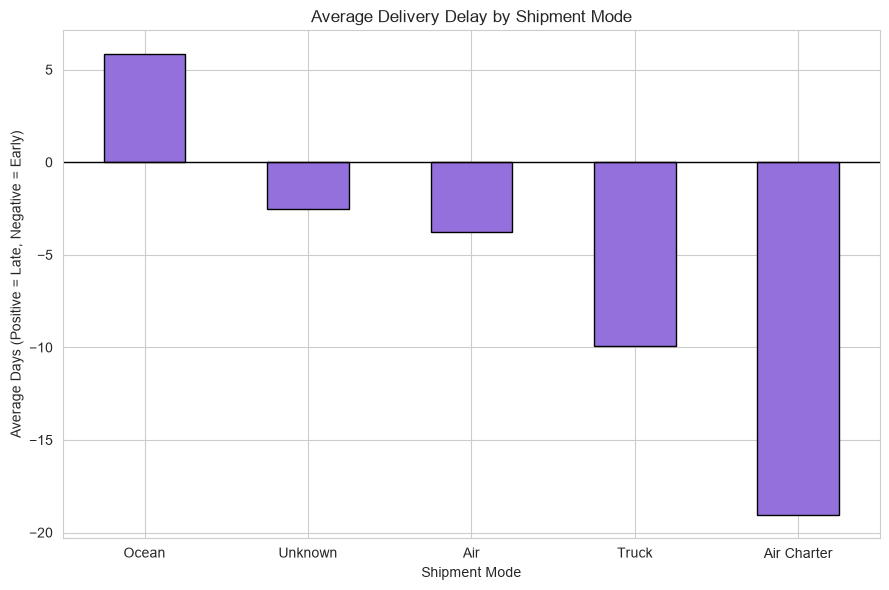

Average Delivery Delay by Shipment Mode:
Shipment Mode
Ocean           5.87
Unknown        -2.51
Air            -3.76
Truck          -9.92
Air Charter   -19.04
Name: Lead Time Days, dtype: float64

Shipment Records by Mode:
Shipment Mode
Air            6113
Air Charter     650
Ocean           371
Truck          2830
Unknown         360
Name: Lead Time Days, dtype: int64


In [26]:
# Chart 9: Average Delivery Delay by Shipment Mode

delay_mode_data = df_clean.copy()

delay_mode_data['Shipment Mode'] = (
    delay_mode_data['Shipment Mode'].fillna('Unknown')
)

average_delay = (
    delay_mode_data
    .groupby('Shipment Mode')['Lead Time Days']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

average_delay.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Average Delivery Delay by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Average Days (Positive = Late, Negative = Early)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Average Delivery Delay by Shipment Mode:")
print(average_delay.round(2))

print("\nShipment Records by Mode:")
print(delay_mode_data.groupby('Shipment Mode')['Lead Time Days'].count())

**1. Why did you pick the specific chart?**

I selected a bar chart to compare the average delivery delay across different shipment modes. It helps identify which transportation modes deliver earlier or later than their scheduled delivery dates.

**2. What is/are the insight(s) found from the chart?**

Ocean shipments had an average delay of 5.87 days, indicating that they were delivered late on average. In contrast, Air shipments were delivered 3.76 days early, Truck shipments 9.92 days early, and Air Charter shipments 19.04 days early on average. The Unknown category had an average of 2.51 days early.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business improve delivery scheduling and select suitable transportation modes. Ocean shipments may require better planning because their average delivery time exceeded the scheduled date, potentially increasing delays and operational costs. However, early delivery averages do not automatically mean better performance, and the number of shipments, delivery requirements, and individual delays should also be considered.

## Chart 10 — Number of Shipments by Delivery Year

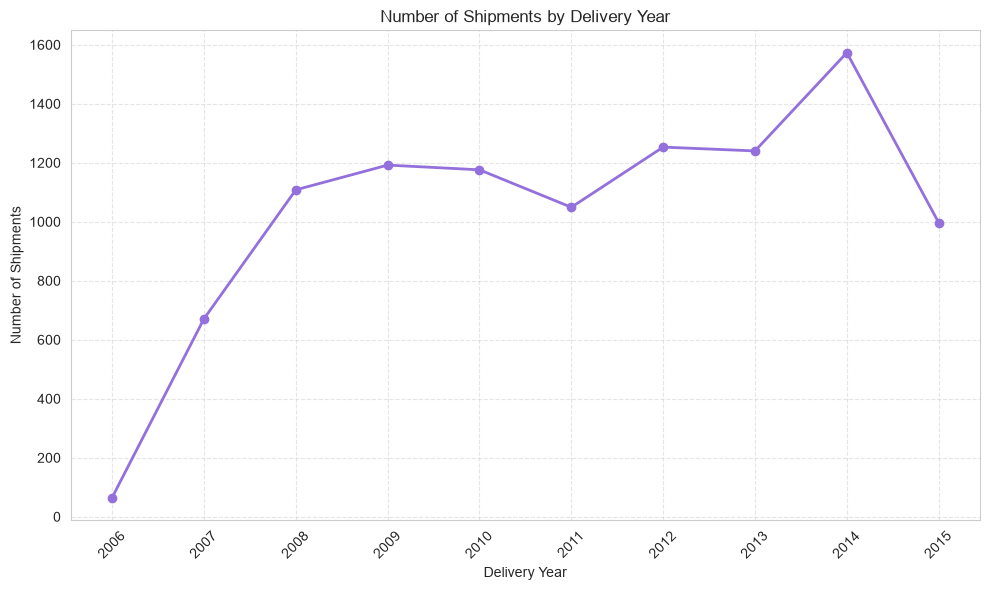

Number of Shipments by Delivery Year:
Delivery Year
2006      65
2007     671
2008    1108
2009    1192
2010    1176
2011    1049
2012    1253
2013    1240
2014    1573
2015     997
Name: count, dtype: int64


In [28]:
# Chart 10: Number of Shipments by Delivery Year

yearly_shipments = (
    df_clean['Delivery Year']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

yearly_shipments.plot(
    kind='line',
    marker='o',
    color='mediumpurple',
    linewidth=2
)

plt.title('Number of Shipments by Delivery Year')
plt.xlabel('Delivery Year')
plt.ylabel('Number of Shipments')
plt.xticks(yearly_shipments.index.astype(int), rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Number of Shipments by Delivery Year:")
print(yearly_shipments)

**1. Why did you pick the specific chart?**

I selected a line chart to analyze changes in the number of shipments over time. It helps identify trends, increases, and decreases in yearly shipment volumes in the FedEx dataset.

**2. What is/are the insight(s) found from the chart?**

Shipment volume generally increased from 65 shipments in 2006 to a peak of 1,573 in 2014, before decreasing to 997 in 2015. The data shows fluctuations over the years, with a notable increase in 2014 followed by a decline in 2015.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business plan transportation capacity, staffing, and inventory according to shipment trends. The decline from 1,573 shipments in 2014 to 997 in 2015 may indicate reduced shipment activity or incomplete records, which should be investigated before making business decisions. Understanding these changes can support better resource allocation and operational planning.

## Chart 11 — Average Line Item Value by Shipment Mode

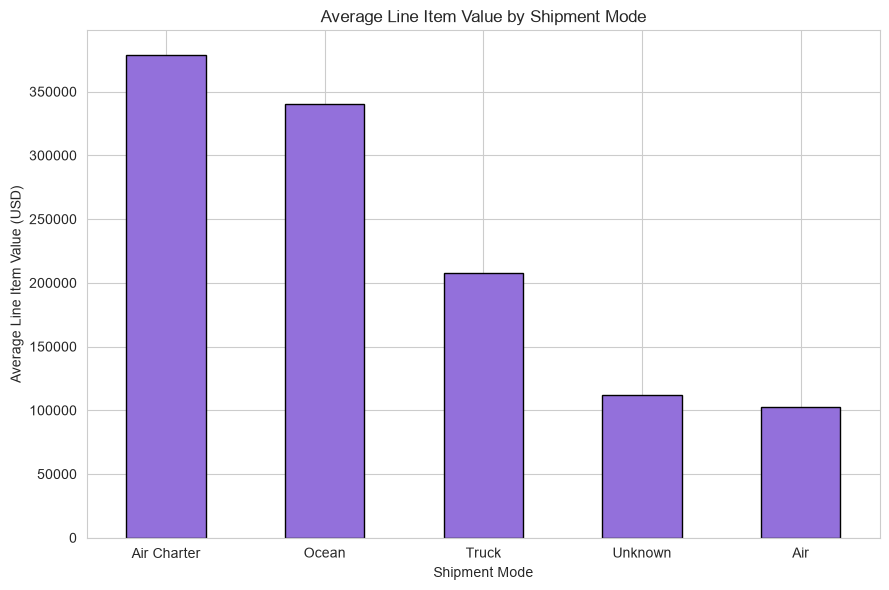

Average Line Item Value by Shipment Mode:
Shipment Mode
Air Charter    379034.20
Ocean          340102.27
Truck          207555.61
Unknown        112127.71
Air            102615.07
Name: Line Item Value, dtype: float64

Number of Records by Shipment Mode:
Shipment Mode
Air            6113
Air Charter     650
Ocean           371
Truck          2830
Unknown         360
Name: Line Item Value, dtype: int64


In [29]:
# Chart 11: Average Line Item Value by Shipment Mode

value_mode_data = df_clean.copy()

value_mode_data['Shipment Mode'] = (
    value_mode_data['Shipment Mode'].fillna('Unknown')
)

average_value = (
    value_mode_data
    .groupby('Shipment Mode')['Line Item Value']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

average_value.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Average Line Item Value by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Average Line Item Value (USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Average Line Item Value by Shipment Mode:")
print(average_value.round(2))

print("\nNumber of Records by Shipment Mode:")
print(value_mode_data.groupby('Shipment Mode')['Line Item Value'].count())

**1. Why did you pick the specific chart?**

I selected a bar chart to compare the average line item value across different shipment modes. It helps identify which transportation modes are associated with higher-value shipments in the FedEx dataset.

**2. What is/are the insight(s) found from the chart?**

Air Charter had the highest average line item value at USD 379,034.20, followed by Ocean at USD 340,102.27 and Truck at USD 207,555.61. Air had the lowest average value among the known shipment modes at USD 102,615.07.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business plan shipment handling, insurance, and risk management according to the value of goods transported. Higher-value shipments carried by Air Charter and Ocean may require appropriate security and insurance arrangements. However, higher average shipment value does not necessarily mean higher profitability, so transportation costs and shipment requirements should also be considered.

## Chart 12 — Average Delivery Delay by Product Group

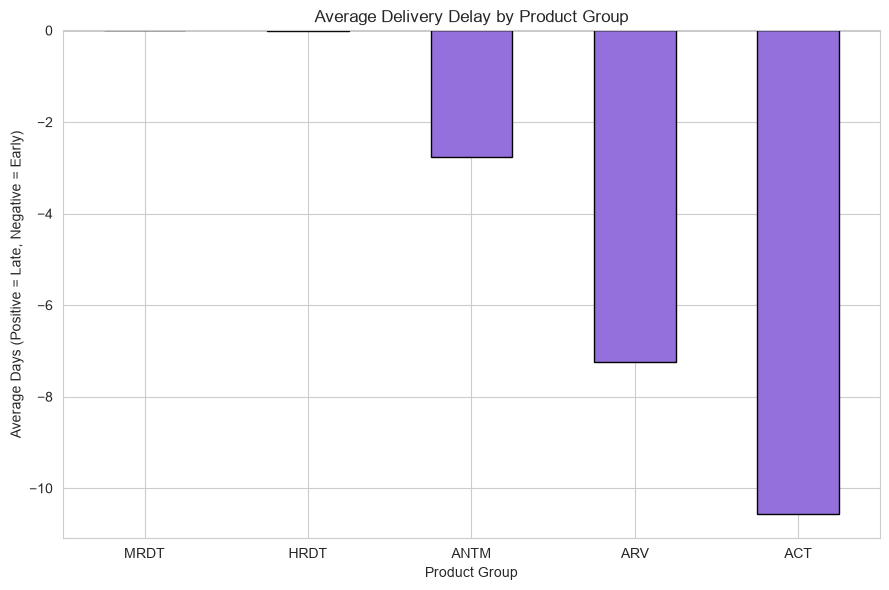

Average Delivery Delay by Product Group:
Product Group
MRDT     0.00
HRDT    -0.01
ANTM    -2.77
ARV     -7.24
ACT    -10.56
Name: Lead Time Days, dtype: float64

Shipment Records by Product Group:
Product Group
ACT       16
ANTM      22
ARV     8550
HRDT    1728
MRDT       8
Name: Lead Time Days, dtype: int64


In [30]:
# Chart 12: Average Delivery Delay by Product Group

product_delay = (
    df_clean.groupby('Product Group')['Lead Time Days']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

product_delay.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.axhline(0, color='black', linewidth=1)

plt.title('Average Delivery Delay by Product Group')
plt.xlabel('Product Group')
plt.ylabel('Average Days (Positive = Late, Negative = Early)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Average Delivery Delay by Product Group:")
print(product_delay.round(2))

print("\nShipment Records by Product Group:")
print(df_clean.groupby('Product Group')['Lead Time Days'].count())

**1. Why did you pick the specific chart?**

I selected a bar chart to compare the average delivery delay across different product groups. It helps identify which product groups are delivered early or late compared with their scheduled delivery dates.

**2. What is/are the insight(s) found from the chart?**

MRDT had an average delivery delay of 0 days, while HRDT was nearly on schedule at -0.01 days. ANTM shipments were delivered 2.77 days early on average, ARV shipments 7.24 days early, and ACT shipments 10.56 days early. However, ACT, ANTM, and MRDT have very few records, so their averages should be interpreted cautiously.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business improve delivery scheduling and plan logistics according to product group requirements. ARV and HRDT account for most records, so monitoring their delivery performance can support operational planning. Although some smaller groups show earlier average deliveries, their low shipment counts limit the reliability of comparisons, and early delivery does not necessarily indicate better performance in every situation.

## Chart 13 — Average Freight Cost by Product Group

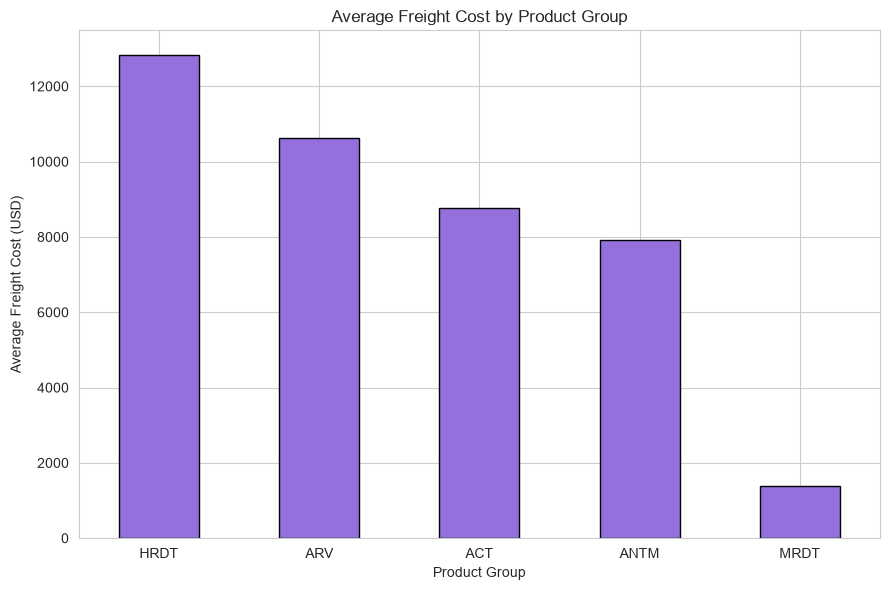

Average Freight Cost by Product Group:
Product Group
HRDT    12840.37
ARV     10637.51
ACT      8759.20
ANTM     7929.77
MRDT     1388.14
Name: Freight_Cost_USD_numeric, dtype: float64

Valid Numeric Freight Records by Product Group:
Product Group
ACT       13
ANTM      19
ARV     4790
HRDT    1370
MRDT       6
Name: Freight_Cost_USD_numeric, dtype: int64


In [31]:
# Chart 13: Average Freight Cost by Product Group

freight_product_data = df_clean.dropna(
    subset=['Freight_Cost_USD_numeric', 'Product Group']
)

average_freight_product = (
    freight_product_data
    .groupby('Product Group')['Freight_Cost_USD_numeric']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

average_freight_product.plot(
    kind='bar',
    color='mediumpurple',
    edgecolor='black'
)

plt.title('Average Freight Cost by Product Group')
plt.xlabel('Product Group')
plt.ylabel('Average Freight Cost (USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Average Freight Cost by Product Group:")
print(average_freight_product.round(2))

print("\nValid Numeric Freight Records by Product Group:")
print(
    freight_product_data
    .groupby('Product Group')['Freight_Cost_USD_numeric']
    .count()
)

**1. Why did you pick the specific chart?**

I selected a bar chart to compare the average freight cost across different product groups. It helps identify which product groups are associated with higher transportation expenses in the FedEx dataset.

**2. What is/are the insight(s) found from the chart?**

HRDT had the highest average freight cost at USD 12,840.37, followed by ARV at USD 10,637.51 and ACT at USD 8,759.20. MRDT had the lowest average at USD 1,388.14. However, MRDT had only 6 valid numeric freight records, while HRDT had 1,370 and ARV had 4,790, so the smaller groups' averages should be interpreted cautiously.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business monitor transportation expenses and identify opportunities to optimize freight spending across product groups. The higher average freight cost for HRDT may require further investigation into shipment weight, distance, and transportation mode. If these costs are not managed effectively, they may increase operational expenses; however, average freight cost alone does not establish which product group is less profitable.

## Chart 14 — Delivery Status by Product Group

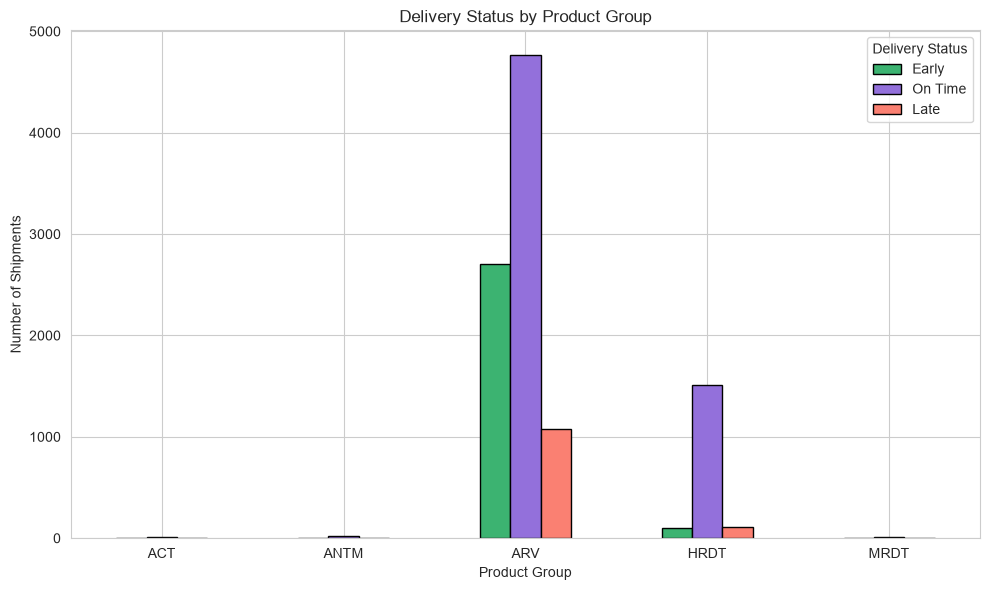

Delivery Status Counts by Product Group:
Delivery Status  Early  On Time  Late
Product Group                        
ACT                  1       15     0
ANTM                 1       21     0
ARV               2707     4770  1073
HRDT               105     1510   113
MRDT                 0        8     0

Late Delivery Percentage by Product Group:
Product Group
ACT      0.00
ANTM     0.00
ARV     12.55
HRDT     6.54
MRDT     0.00
dtype: float64


In [32]:
# Chart 14: Delivery Status by Product Group

status_product_counts = pd.crosstab(
    df_clean['Product Group'],
    df_clean['Delivery Status']
)

status_product_counts = status_product_counts[
    ['Early', 'On Time', 'Late']
]

status_product_counts.plot(
    kind='bar',
    figsize=(10, 6),
    color=['mediumseagreen', 'mediumpurple', 'salmon'],
    edgecolor='black'
)

plt.title('Delivery Status by Product Group')
plt.xlabel('Product Group')
plt.ylabel('Number of Shipments')
plt.xticks(rotation=0)
plt.legend(title='Delivery Status')
plt.tight_layout()
plt.show()

print("Delivery Status Counts by Product Group:")
print(status_product_counts)

print("\nLate Delivery Percentage by Product Group:")
print(
    (
        status_product_counts['Late']
        / status_product_counts.sum(axis=1)
        * 100
    ).round(2)
)

**1. Why did you pick the specific chart?**

I selected a grouped bar chart to compare delivery statuses across different product groups. It helps identify which product groups experience more late deliveries and evaluate their delivery performance.

**2. What is/are the insight(s) found from the chart?**

ARV had the highest late-delivery percentage at 12.55%, with 1,073 late shipments out of 8,550 records. HRDT had a late-delivery percentage of 6.54%, with 113 late shipments out of 1,728 records. ACT, ANTM, and MRDT had no recorded late deliveries, but these groups had very few shipments, so their results should be interpreted cautiously.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business identify product groups that need closer delivery monitoring and improve logistics planning. The higher late-delivery rate for ARV may contribute to customer dissatisfaction and operational costs, making it important to investigate the causes of its delays. The results for smaller product groups should not be treated as proof of consistently reliable delivery because their shipment counts are limited.

## Chart 15 — Freight Cost, Weight, and Shipment Mode

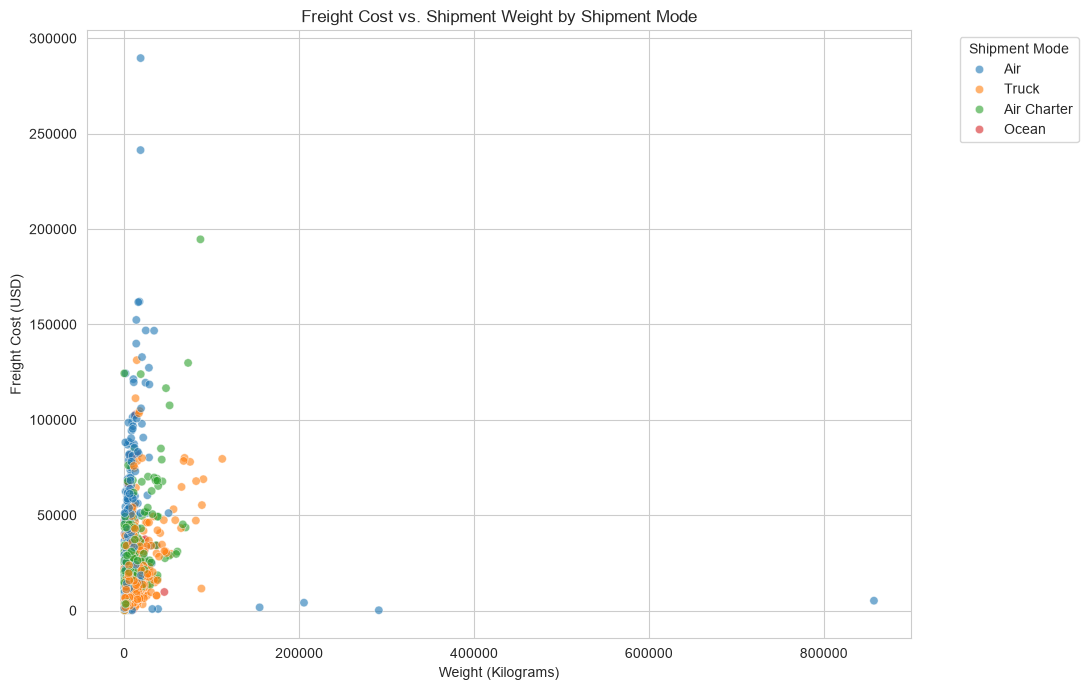

Valid records analyzed: 5963

Average Weight and Freight Cost by Shipment Mode:
               Weight_kg_numeric  Freight_Cost_USD_numeric
Shipment Mode                                             
Air                      1992.92                  10489.07
Air Charter              7686.46                  21004.15
Ocean                    6877.39                  12733.08
Truck                    6404.72                  10199.09


In [33]:
# Chart 15: Freight Cost vs. Shipment Weight by Shipment Mode

multivariate_data = df_clean.dropna(
    subset=[
        'Weight_kg_numeric',
        'Freight_Cost_USD_numeric',
        'Shipment Mode'
    ]
).copy()

multivariate_data = multivariate_data[
    (multivariate_data['Weight_kg_numeric'] > 0) &
    (multivariate_data['Freight_Cost_USD_numeric'] >= 0)
]

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=multivariate_data,
    x='Weight_kg_numeric',
    y='Freight_Cost_USD_numeric',
    hue='Shipment Mode',
    alpha=0.6
)

plt.title('Freight Cost vs. Shipment Weight by Shipment Mode')
plt.xlabel('Weight (Kilograms)')
plt.ylabel('Freight Cost (USD)')
plt.legend(title='Shipment Mode', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("Valid records analyzed:", len(multivariate_data))

print("\nAverage Weight and Freight Cost by Shipment Mode:")
print(
    multivariate_data.groupby('Shipment Mode')[
        ['Weight_kg_numeric', 'Freight_Cost_USD_numeric']
    ].mean().round(2)
)

**1. Why did you pick the specific chart?**

I selected a scatter plot to examine the relationship between shipment weight and freight cost while distinguishing shipments by transportation mode. It helps compare multiple variables and identify patterns in the FedEx dataset.

**2. What is/are the insight(s) found from the chart?**

Air Charter had the highest average freight cost at USD 21,004.15 and an average shipment weight of 7,686.46 kg. Ocean shipments averaged 6,877.39 kg with a freight cost of USD 12,733.08, while Air shipments had the lowest average weight at 1,992.92 kg and an average freight cost of USD 10,489.07. These results suggest that freight costs vary by shipment mode and weight, although other factors also influence costs.

**3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.**

These insights can help the business improve freight budgeting and select suitable transportation modes based on shipment weight and operational requirements. The high average freight cost for Air Charter may increase logistics expenses, so reviewing its use for shipments that do not require urgent delivery could reveal savings opportunities. However, transportation decisions should also consider distance, delivery urgency, and service requirements rather than weight alone.

### Key Findings

1. **Country-wise distribution:** South Africa had the highest number of records (1,406), followed by Nigeria (1,194) and Côte d'Ivoire (1,083). This indicates that shipment records were concentrated in a few countries.

2. **Shipment mode distribution:** Air transportation was the most frequently recorded shipment mode, with 6,113 records, followed by Truck with 2,830. This shows that air and truck transportation played major roles in the recorded logistics operations.

3. **Product group distribution:** ARV was the largest product group, with 8,550 records, followed by HRDT with 1,728. Therefore, delivery planning for these groups is particularly important.

4. **Vendor distribution:** SCMS from RDC accounted for 5,404 records, considerably more than any other vendor entry. Its operational role should be verified before interpreting this concentration as supplier dependency.

5. **Freight cost patterns:** Air Charter had the highest average recorded freight cost among the compared shipment modes at USD 21,052.14, while Truck had an average of USD 10,176.41. Shipment mode appears to be an important factor to investigate when managing freight expenses.

6. **Weight and freight relationship:** Shipment weight and freight cost had a weak positive correlation of 0.232. This suggests that heavier shipments tend to have somewhat higher freight costs, but weight alone cannot explain the cost differences.

7. **Delivery performance:** Out of 10,324 records, 6,324 shipments were delivered on time, 2,814 early, and 1,186 late. Approximately 11.5% of shipments were late, indicating an opportunity to improve delivery reliability.

8. **Delivery performance by shipment mode:** Ocean shipments had the highest late-delivery rate at 17.52%, followed by Truck at 16.08%. These modes may require further investigation into scheduling and transit times.

9. **Yearly shipment trend:** Shipment volume reached its highest recorded level in 2014, with 1,573 shipments, before declining to 997 in 2015. The decline should be investigated to determine whether it reflects operational changes or incomplete records.

10. **Product group delivery performance:** ARV had a late-delivery rate of 12.55%, compared with 6.54% for HRDT. Since ARV represents the largest product group, improving its delivery performance could have a meaningful operational impact.

11. **Freight cost by product group:** HRDT had an average recorded freight cost of USD 12,840.37, while ARV averaged USD 10,637.51. Differences in shipment weight, mode, distance, and delivery requirements may help explain this variation.

12. **Shipment value:** Air Charter and Ocean shipments had higher average line item values than Air shipments. This suggests that shipment value should be considered when planning security, handling, and insurance arrangements.

Overall, the analysis highlights differences in shipment volume, freight costs, and delivery performance across countries, vendors, shipment modes, and product groups.

### Business Recommendations

1. **Improve late-delivery monitoring:** Investigate the 1,186 late shipments to identify recurring causes, such as scheduling issues, route conditions, or transportation delays.

2. **Review Ocean and Truck performance:** Since these modes had higher late-delivery rates than Air, review their planned transit times, route schedules, and delivery processes. Any changes should account for distance, shipment requirements, and cost.

3. **Optimize transportation costs:** Air Charter had the highest average recorded freight cost among the compared modes. Evaluate whether less expensive transportation options are suitable for shipments that do not require urgent delivery.

4. **Focus on high-volume product groups:** ARV and HRDT account for most shipment records. Prioritize inventory planning, shipment tracking, and delivery monitoring for these groups.

5. **Investigate ARV delays:** Examine the causes of the 1,073 late ARV shipments to identify opportunities to improve scheduling and delivery reliability.

6. **Strengthen freight cost estimation:** Since weight had only a weak positive correlation with freight cost, include additional factors such as shipment mode, distance, urgency, and shipment characteristics when estimating transportation expenses.

7. **Improve vendor coordination:** Review the high volume of records associated with SCMS from RDC and confirm its role in the supply chain. Use the findings to improve coordination and reporting where necessary.

8. **Plan resources using shipment trends:** Use yearly shipment volumes and country-level record counts to guide staffing, transport capacity, and operational planning. Investigate the decline in records in 2015 before making major resource decisions.

9. **Review data quality:** Improve the recording of shipment modes, weights, freight costs, and other operational details so that future reports provide more complete and reliable comparisons.

These recommendations can help the business improve delivery reliability, control transportation expenses, and make better-informed logistics decisions.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

I recommend that the client focus on improving delivery reliability, reducing transportation costs, and strengthening logistics planning. The business should investigate late deliveries, particularly for Ocean and Truck shipments, optimize shipment modes based on cost and urgency, and prioritize delivery monitoring for high-volume product groups such as ARV and HRDT. Additionally, improving data quality and using historical shipment trends for resource planning can support better decision-making, reduce operational inefficiencies, and improve overall supply chain performance.

# **Conclusion**

The Exploratory Data Analysis of the FedEx dataset examined shipment distribution, transportation modes, vendors, product groups, freight costs, shipment weight, and delivery performance through 15 visualizations.

The analysis found that South Africa had the highest number of records, Air was the most frequently recorded shipment mode, and ARV was the dominant product group. Freight costs varied across transportation modes and product groups, while the weak positive relationship between shipment weight and freight cost showed that other factors must also be considered when estimating transportation expenses.

Delivery performance was another important finding. Although most shipments were delivered on time or early, 1,186 shipments were late. Ocean and Truck shipments had higher late-delivery rates than Air shipments, and ARV had the highest late-delivery rate among the major product groups examined.

The analysis suggests that improving delivery scheduling, investigating late shipments, optimizing transportation choices, and strengthening data quality could support better logistics planning and cost management.

However, the findings should be interpreted in the context of missing values, historical records, and differences in group sizes. Further investigation using more complete and recent data would help validate these patterns and support more reliable business decisions.

Overall, this project helped demonstrate how Exploratory Data Analysis can transform raw logistics data into meaningful insights and practical recommendations for operational improvement.